### 차원의 저주(Curse of Dimensionality)
**데이터의 차원(변수의 개수)이 증가함에 따라,**<br>
**공간의 부피가 기하급수적으로 커져 데이터가 희소해지고 머신러닝·통계 모델의 성능이 떨어지는 현상이다.** </br>

수학자 리처드 벨맨(Richard E. Bellman)이 처음 사용한 개념이다.<br>

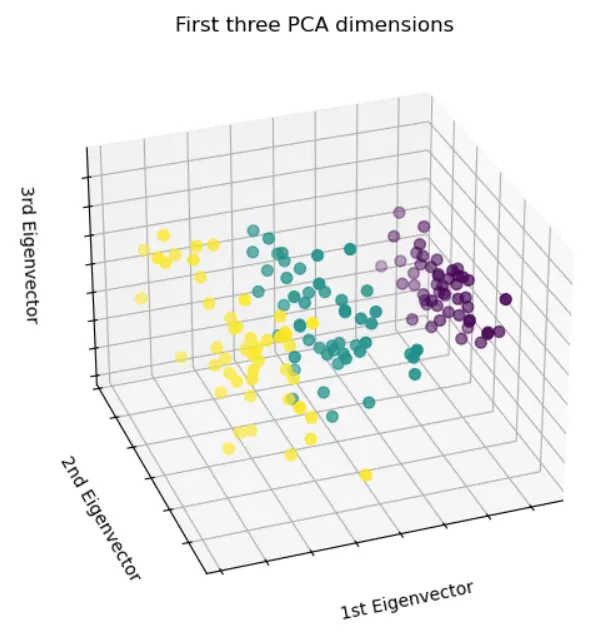

### 차원의 저주 현상에서의 문제점
- 데이터 희소성(sparsity)
- 계산 비용 증가(computing expense)
- 과적합(overfitting)
- 거리의 의미 상실(loss of distance meaning)
- 성능 저하(performance degraduation)


### 휴즈 현상(Hughes Phenomenon)
피처(특징) 수가 증가함에 따라 분류기의 성능도 증가하다가 <br>
최적의 특징 수에 도달하면 성능이 최상에 이르는 현상을 나타낸다. </br>
그러나, 동일한 크기의 훈련 세트를 기준으로 더 많은 특징을 추가하면 분류기의 성능이 저하된다.

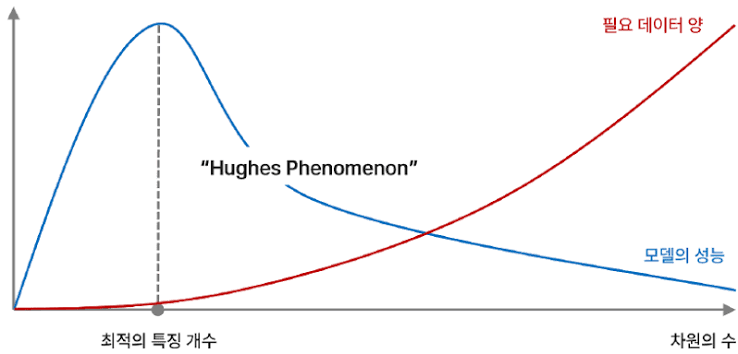

### 차원의 저주 - 거리 함수(Distance Function)
dataset의 차원이 증가한다는 것은 <br>
해당하는 유클리드 공간에서 각 관찰을 나타내는 특징 벡터에 더 많은 항목이 추가된다는 것을 의미한다.</br>

2차원 벡터 사이의 거리를 계산하는 유클리드 거리(공식)

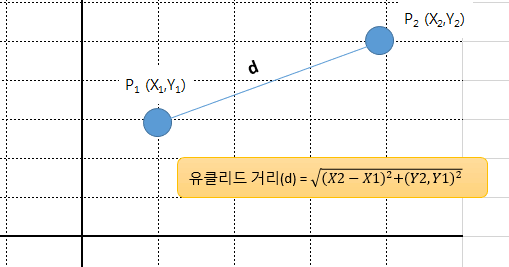

## 차원의 저주를 해결하는 주요 방법
- 주성분 분석(PCA):

- 선형 판별 분석(LDA, Linear Discriminant Analysis):

- t-SNE(t-Distributed Stochastic Neighbor Embedding) 및 UMAP:

- 특성 선택(Feautre Selection):

- Autoencoder:

## 주성분 분석(PCA: Principle Component Analysis)
- 주성분이란, 전체 데이터(독립변수들:x)의 분산을 가장 잘 설명하는 성분을 말한다.

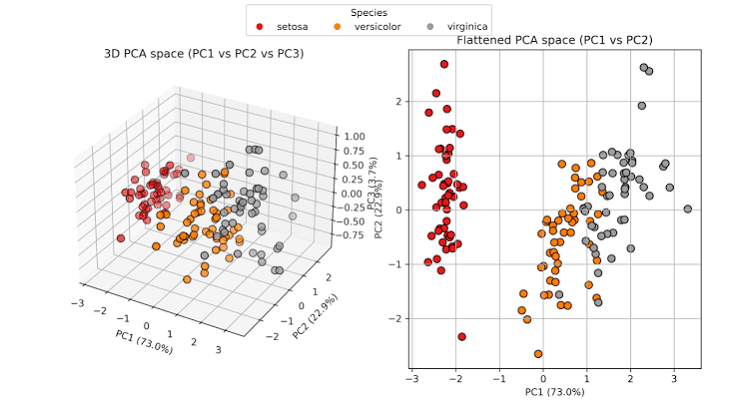

### (**변수의 개수 = 차원의 개수**)
#### : **차원이 증가할수록 데이터가 표현해야 하는 공간은 복잡해진다.**

따라서, 변수가 너무 많아 **기존 변수들을 조합하여 만든
<br>새로운 변수**를 가지고 모델링을 하려고 할때 주로 PCA를 사용한다.</br>

- 기존의 컬럼을 새롭게 해석하여 저차원의 초평면에 투영한다.

- 여러 변수 간에 존재하는 상관관계를 이용하는 차원축소 방법으로,<br>
  데이터를 축에 사영했을 때 분산이 가장 높은 축을 찾아서 그 축을 새로운 주성분으로 결정하는 방법이다.<br>

- 다시 말하면, </br>
  제일 먼저 가장 큰 분산을 기반으로 첫번째 축을 생성하고, 이 벡터 축에 직각이 되는 벡터를 두번째 축으로 선택한다.</br>

- 세 번째 축은 다시 두 번째 축과 직각이 되는 벡터를 축으로 설정한다.<br>
  이렇게 데이터를 충분히 설명할 수 있는 몇개의 주성분으로 압축한다.</br>

### **(1) Feature Selection (변수 추출)**
- 상관관계가 높은 컬럼 제거
- 분석과 관련이 없는 컬럼 제거(ID, 관리자 코드, 데이터 업데이트 일자 등)
- EDA에서 상관관계가 매우 높은 설명변수는 유사한 정보를 가지고 있을 확률이 높음
  (그 중 하나만을 선택하여 분석)  

### **(2) Dimensionality Reduction (차원 축소)**


In [ ]:
'''
PCA Process - 1
: 주성분 선정에 영향을 주는 이상치 제거 및 스케일링을 수행한다.

수치형 데이터만 추출
features = ['seq_col1','seq_col2']
x = data[features]

수치형 변수 정규화
from sklearn.preprocessing import StandardScaler
x = StandardScaler().fit_transform(x)
'''

import pandas as pd
from sklearn.datasets import load_iris

iris = load_iris()
iris = pd.DataFrame(iris.data, columns=iris.feature_names)
iris['Class'] = load_iris().target
iris['Class'] = iris['Class'].map({0:'Setosa',
                                   1:'Versicolour',
                                   2:'Virginica'})
# 수치형 변수 1,2
# features = ['seq_col1','seq_col2']
x = iris.drop(columns='Class')

from sklearn.preprocessing import StandardScaler
x = StandardScaler().fit_transform(x)

pd.DataFrame(x).head()



,0,1,2,3
0,-0.900681,1.019004,-1.340227,-1.315444
1,-1.143017,-0.131979,-1.340227,-1.315444
2,-1.385353,0.328414,-1.397064,-1.315444
3,-1.506521,0.098217,-1.283389,-1.315444
4,-1.021849,1.249201,-1.340227,-1.315444


In [2]:
'''
PCA Process - 2
주성분 추출
: 생성할 주성분의 개수를 임시로 선택한 후,
  scikit-learn의 PCA를 사용하여 주성분을 추출한다

여기에서,
singular_values 는 
전체 데이터에서 해당 모델(설정된 주성분의 개수)로 설명할 수 있는 분산의 비율,

explained_variance_ratio_ 는 
전체 데이터에서 각 주성분이 설명할 수 있는 분산의 비율을 의미한다.

singular_values_와 explained_variance_ratio_를 사용하여
주성분의 개수를 구할 수 있으나
Scree plot을 확인하여 정하기도 한다.

from sklearn.decomposition import PCA
pca = PCA(n_components=int)  # n_components: 생성할 주성분의 개수
pca_fit = pca.fit(x)

print('고유 값: ', pca.singular_values_)
print('분산 설명력: ', pca.explained_variance_ratio_)
'''

from sklearn.decomposition import PCA
pca = PCA(n_components = 4)
pca_fit = pca.fit(x)

print('고유 값: ', pca.singular_values_)
print('분산 설명력: ', pca.explained_variance_ratio_)

고유 값:  [20.92306556 11.7091661   4.69185798  1.76273239]
분산 설명력:  [0.72962445 0.22850762 0.03668922 0.00517871]


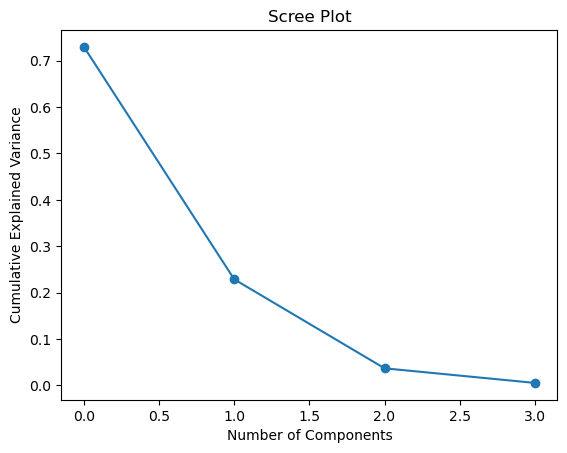

In [3]:
'''
PCA Process - 3
Sree Plot으로 사용할 주성분의 개수 정하기

(Scree Plot )
- 주성분 각각으로 설명할 수 있는 분산의 정도를 
  점으로 표시하고 각 점들을 이은 선이다.
- 주성분 개수가 증가할수록 Scree Plot의 기울기(분산의 변화 정도)는 감소한다.
  보통 플롯이 기울기가 급격히 감소하는 지점이 직전까지를 주성분으로 선택한다.

import matplotlib.pyplot as plt
plt.title('Scree Plot')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.plot(pca.explained_variance_ratio_, 'o-')
plt.show()
'''
import matplotlib.pyplot as plt
plt.title('Scree Plot')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.plot(pca.explained_variance_ratio_, 'o-')
plt.show()

In [4]:
'''
PCA Process - 4
새로운 데이터프레임 확인
- 주성분의 수를 정한 뒤, 주성분을 다시 추출하여 주성분 객체를 생성하고,
 fit_transform()을 수행하여 원하는 개수의 주성분을 가진 df을 만든다.

 
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
principalComponents = pca.fit_transform(x)
principalDf = pd.DataFrame(data=principalComponents, columns=['pc1','pc2'])

'''
pca = PCA(n_components = 2)
principalComponents = pca.fit_transform(x)
principal_iris = pd.DataFrame(data=principalComponents,
                            columns=['pc1', 'pc2'])
principal_iris.head()

,pc1,pc2
0,-2.264703,0.480027
1,-2.080961,-0.674134
2,-2.364229,-0.341908
3,-2.299384,-0.597395
4,-2.389842,0.646835


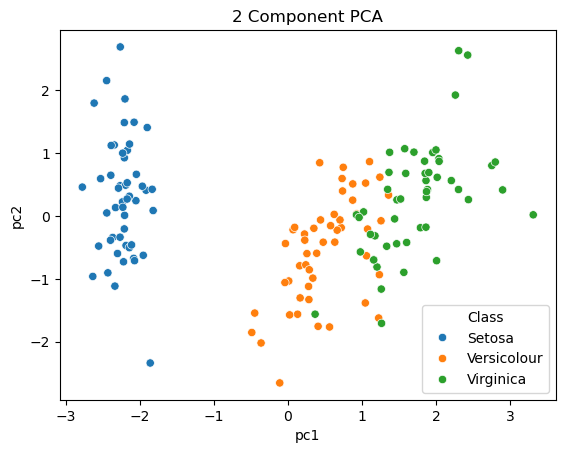

In [6]:
'''
PCA Process - 5
주성분 산포도 확인

'''

import matplotlib.pyplot as plt
import seaborn as sns

plt.title('2 Component PCA')
sns.scatterplot(x='pc1',
                y='pc2',
                hue=iris.Class,
                data=principal_iris)
plt.show()